# Tugas Praktikum JS09 - Dataset PBL
## Klasifikasi Berita Hoaks Menggunakan Naive Bayes dan kNN


### 1. Load dataset PBL


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
print('Distribusi kelas (1: Hoaks, 0: Valid):')
print(df['label'].value_counts())
df.head()


Dimensi data: (1498, 2)
Distribusi kelas (1: Hoaks, 0: Valid):
label
1    749
0    749
Name: count, dtype: int64


,teks_bersih,label
0,presiden prabowo minta maaf ikut bop akan kemb...,1
1,video presiden prabowo akan membagikan bantuan...,1
2,pemerintah kota tangerang selatan akan legalka...,1
3,tautan rekrutmen cpns kementerian imigrasi,1
4,ramuan rebusan jahe kunyit kencur dan serai be...,1


### 2. Ekstraksi Fitur Teks (TF-IDF)


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X = df['teks_bersih']
y = df['label']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(max_features=1000)
X_train = tfidf.fit_transform(X_train_raw)
X_test = tfidf.transform(X_test_raw)

print('Ukuran data train:', X_train.shape)
print('Ukuran data test :', X_test.shape)


Ukuran data train: (1198, 1000)
Ukuran data test : (300, 1000)


### 3. Klasifikasi Menggunakan Naive Bayes (MultinomialNB)


In [3]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

acc_nb = accuracy_score(y_test, y_pred_nb)
print(f'Akurasi Naive Bayes: {acc_nb * 100:.2f}%')
print('Classification Report Naive Bayes:')
print(classification_report(y_test, y_pred_nb, target_names=['Valid', 'Hoaks']))


Akurasi Naive Bayes: 87.33%
Classification Report Naive Bayes:
              precision    recall  f1-score   support

       Valid       0.89      0.85      0.87       150
       Hoaks       0.85      0.90      0.88       150

    accuracy                           0.87       300
   macro avg       0.87      0.87      0.87       300
weighted avg       0.87      0.87      0.87       300



### 4. Klasifikasi Menggunakan k-Nearest Neighbors (kNN)


In [4]:
from sklearn.neighbors import KNeighborsClassifier

# Evaluasi kNN dengan beberapa variasi k (k=3, 5, 7)
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k, metric='cosine')
    knn.fit(X_train, y_train)
    y_pred_knn = knn.predict(X_test)
    acc_k = accuracy_score(y_test, y_pred_knn)
    print(f'Akurasi kNN (k={k}, metric=cosine): {acc_k * 100:.2f}%')

# Model kNN terbaik untuk evaluasi lanjutan
knn_best = KNeighborsClassifier(n_neighbors=5, metric='cosine')
knn_best.fit(X_train, y_train)
y_pred_knn_best = knn_best.predict(X_test)
acc_knn = accuracy_score(y_test, y_pred_knn_best)

print('Classification Report kNN (k=5):')
print(classification_report(y_test, y_pred_knn_best, target_names=['Valid', 'Hoaks']))


Akurasi kNN (k=3, metric=cosine): 83.00%


Akurasi kNN (k=5, metric=cosine): 81.67%
Akurasi kNN (k=7, metric=cosine): 82.33%
Classification Report kNN (k=5):
              precision    recall  f1-score   support

       Valid       0.89      0.73      0.80       150
       Hoaks       0.77      0.91      0.83       150

    accuracy                           0.82       300
   macro avg       0.83      0.82      0.82       300
weighted avg       0.83      0.82      0.82       300



### 5. Confusion Matrix dan Perbandingan Model


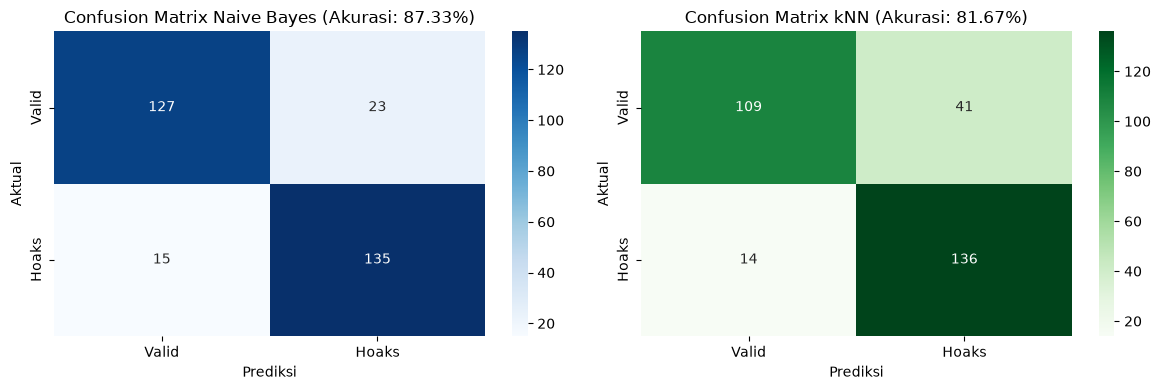

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Valid', 'Hoaks'], yticklabels=['Valid', 'Hoaks'])
axes[0].set_title(f'Confusion Matrix Naive Bayes (Akurasi: {acc_nb*100:.2f}%)')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

cm_knn = confusion_matrix(y_test, y_pred_knn_best)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Valid', 'Hoaks'], yticklabels=['Valid', 'Hoaks'])
axes[1].set_title(f'Confusion Matrix kNN (Akurasi: {acc_knn*100:.2f}%)')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()
